# Data Understanding of the Heart Diagnoses file

This file contains the data understanding task applied on the Heart Diagnoses CSV file.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))
from src.utils import data_understanding as du

heart_diagnoses_df = pd.read_csv("../../data/raw/heart_diagnoses_1.csv")


In [2]:
#print the number  of columns and rows of the dataset
heart_diagnoses_shape=heart_diagnoses_df.shape
print("Number of rows and columns in heart diagnoses dataset:",heart_diagnoses_shape)

Number of rows and columns in heart diagnoses dataset: (4864, 25)


In [3]:
#print the columns of the dataset 
heart_diagnoses_df_columns= du.get_cols(heart_diagnoses_df)
print("Columns in heart diagnoses dataset:",heart_diagnoses_df_columns) 

Columns in heart diagnoses dataset: ['note_id', 'subject_id', 'hadm_id', 'note_type', 'note_seq', 'charttime', 'storetime', 'HPI', 'physical_exam', 'chief_complaint', 'invasions', 'X-ray', 'CT', 'Ultrasound', 'CATH', 'ECG', 'MRI', 'reports', 'subject_id_dx', 'icd_code', 'long_title', 'gender', 'age', 'anchor_year', 'dod']


In [4]:
#print the numerical columns of the dataset
heart_diagnoses_df_num_col=du.get_numeric_cols(heart_diagnoses_df)
print("Numerical columns in heart diagnoses dataset:",heart_diagnoses_df_num_col)

Numerical columns in heart diagnoses dataset: ['age', 'anchor_year']


In [5]:
#print the number of duplicate rows
heart_diagnoses_df_duplicate=du.get_num_dups(heart_diagnoses_df)
print("Number of duplicate rows in heart diagnoses dataset:", heart_diagnoses_df_duplicate)

Number of duplicate rows in heart diagnoses dataset: 0


In [6]:
#print the  missing values in each column
heart_diagnoses_df_none=du.get_cols_with_none(heart_diagnoses_df)
print("Missing values in each column of heart diagnoses dataset:\n",heart_diagnoses_df_none)

#number of missing values in each columns 
def get_num_none(df:pd.DataFrame):
  df_missing_values=df.isnull().sum()
  return df_missing_values

Missing values in each column of heart diagnoses dataset:
 note_id            False
subject_id         False
hadm_id            False
note_type          False
note_seq           False
charttime          False
storetime          False
HPI                False
physical_exam      False
chief_complaint     True
invasions           True
X-ray              False
CT                 False
Ultrasound         False
CATH               False
ECG                False
MRI                False
reports            False
subject_id_dx      False
icd_code           False
long_title         False
gender              True
age                 True
anchor_year         True
dod                 True
dtype: bool


In [7]:
#print the summary information of the dataset
print("Summary information of heart diagnoses dataset:")
heart_diagnoses_df.info()

Summary information of heart diagnoses dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4864 entries, 0 to 4863
Data columns (total 25 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   note_id          4864 non-null   object 
 1   subject_id       4864 non-null   int64  
 2   hadm_id          4864 non-null   int64  
 3   note_type        4864 non-null   object 
 4   note_seq         4864 non-null   int64  
 5   charttime        4864 non-null   object 
 6   storetime        4864 non-null   object 
 7   HPI              4864 non-null   object 
 8   physical_exam    4864 non-null   object 
 9   chief_complaint  4852 non-null   object 
 10  invasions        4852 non-null   object 
 11  X-ray            4864 non-null   object 
 12  CT               4864 non-null   object 
 13  Ultrasound       4864 non-null   object 
 14  CATH             4864 non-null   object 
 15  ECG              4864 non-null   object 
 16  MRI         

In [8]:
#print the statistical summary of numerical columns
print("Statistical summary of numerical columns in heart diagnoses dataset:")
du.get_basic_stats(heart_diagnoses_df)

Statistical summary of numerical columns in heart diagnoses dataset:


,age,anchor_year
count,1363.000000,1363.000000
mean,68.978723,2155.620690
std,14.973358,23.400097
min,18.000000,2110.000000
25%,60.000000,2136.000000
50%,70.000000,2157.000000
75%,81.000000,2174.000000
max,95.000000,2206.000000


In [9]:
#calculate the number of hadmission for each patient
grouped_heart_diagnoses = heart_diagnoses_df.groupby('subject_id')['hadm_id'].nunique()
grouped_heart_diagnoses=grouped_heart_diagnoses.reset_index()
grouped_heart_diagnoses.columns=['subjecte_id','num_hadmissions']
print("Number of admissions for each patient in heart diagnoses dataset:\n",grouped_heart_diagnoses)


Number of admissions for each patient in heart diagnoses dataset:
       subjecte_id  num_hadmissions
0        10000980                2
1        10002013                1
2        10002155                1
3        10004457                1
4        10007058                1
...           ...              ...
4387     19998596                1
4388     19998597                1
4389     19998598                1
4390     19998599                1
4391     19998600                1

[4392 rows x 2 columns]


In [10]:
#count the number of rows where the values of storetime is less or equal to the values of charttime:
#to check the data quality control that the time when the diagnosis is stored (storetime) is after or equal to the time when the diagnosis is recorded(chartime)
error = heart_diagnoses_df[heart_diagnoses_df["storetime"] < heart_diagnoses_df["charttime"]]
print("rows where the values of storetime is less  to the values of charttime:")
print(error[["subject_id", "hadm_id", "storetime", "charttime"]])
count = error.shape[0]
print("Number of rows where the values of storetime is less to the values of charttime:",count)





rows where the values of storetime is less  to the values of charttime:
      subject_id   hadm_id            storetime            charttime
249     10581759  23088729  2126-11-17 17:15:00  2126-11-18 03:00:00
340     10803096  28708257  2162-09-28 15:17:00  2162-09-29 03:00:00
683     11495932  26638278  2180-12-07 18:09:00  2180-12-08 03:00:00
1064    12223339  28882233  2162-04-25 13:46:00  2162-04-26 03:00:00
1463    13043387  25087116  2112-11-27 14:29:00  2112-11-28 03:00:00
1683    13513868  24104318  2157-05-18 15:36:00  2157-05-20 03:00:00
1727    13596021  20861215  2182-07-03 20:14:00  2182-07-04 03:00:00
1807    13767908  27341134  2166-08-02 17:45:00  2166-08-03 03:00:00
3873    18129054  20729789  2111-09-19 19:08:00  2111-09-20 03:00:00
Number of rows where the values of storetime is less to the values of charttime: 9


In [11]:
#Pint the first 10 rows of each procedure-related column. 

procedure_cols = ["CT", "MRI", "X-ray", "Ultrasound", "ECG", "CATH", "invasions"]

for col in procedure_cols:
    print(f"\nColonna: {col}")
    for i, val in enumerate(heart_diagnoses_df[col].head(10)):
        print(f"  Riga {i}: {repr(val)}")


Colonna: CT
  Riga 0: '[]'
  Riga 1: "['CHEST: ___\\n1.  Diffuse confluent ground-glass opacities predominantly in \\nthe right upper lobe and right lower lobe most likely represent \\nresidual pulmonary edema, localized to the right lung because of \\ndirection of jet in mitral \\nregurgitation.  \\n2.  Possible pulmonary hypertension. \\n3.  Moderate coronary artery disease.']"
  Riga 2: "['Chest ___.  No CT evidence for pulmonary embolus. \\n2.  Small left pleural effusion with adjacent atelectasis.  \\n3.  Possible calcified splenic artery aneurysm in the region of \\nthe hilum.']"
  Riga 3: "['anteriorly, no \\ncrackles, wheezes or rhonchi.  \\nABDOMEN: Soft, NTND. No HSM or tenderness. Abd aorta not \\nenlarged by palpation. No abdominial bruits.  \\nEXTREMITIES: No c/c/e. Femoral sheath in place in right groin.  \\nSKIN: No stasis dermatitis, ulcers, scars, or xanthomas.  \\nPULSES:  \\nRight: Carotid 2+ DP 2+ ___ 2+  \\nLeft: Carotid 2+ DP 2+ ___ 2+  \\n\\n']"
  Riga 4: "['/MR

In [12]:
# Mean number of notes per hadmission
avg_notes_per_hadm = heart_diagnoses_df["note_seq"].mean()
print(" Avarage number of notes per hadmission:", avg_notes_per_hadm)

 Avarage number of notes per hadmission: 14.690995065789474


<Axes: xlabel='note_seq', ylabel='Count'>

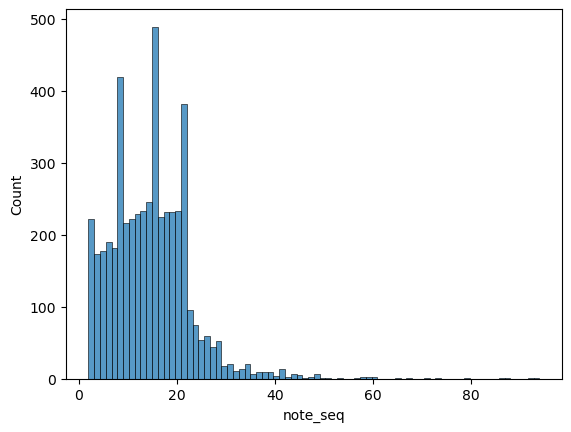

In [13]:
#distribution of the number of notes per hadmission
sns.histplot(heart_diagnoses_df, x="note_seq")


In [14]:
#Print the number of Female, Male, and the Total (F + M) with that ICD code
totals= du.get_ICD_groups(heart_diagnoses_df)
print(totals)

gender        F      M  total
icd_code                     
I20         8.0   10.0   18.0
I21       167.0  295.0  462.0
I22         2.0    NaN    2.0
I24         2.0    5.0    7.0
I25        46.0   93.0  139.0
I30        15.0   12.0   27.0
I31        30.0   22.0   52.0
I33         2.0    8.0   10.0
I34         4.0    2.0    6.0
I35        17.0   32.0   49.0
I36         1.0    NaN    1.0
I40         1.0    6.0    7.0
I42         4.0    6.0   10.0
I44        10.0    7.0   17.0
I47        13.0   19.0   32.0
I48        71.0   74.0  145.0
I49         7.0    6.0   13.0
I50       157.0  158.0  315.0


In [15]:
#associate at each icd_code the patology name
unique_codes = heart_diagnoses_df[["icd_code", "long_title"]].drop_duplicates()
print(unique_codes)

     icd_code                                         long_title
0         I50                                      Heart failure
1         I21                        Acute myocardial infarction
4         I35                Nonrheumatic aortic valve disorders
6         I25                     Chronic ischemic heart disease
12        I48                    Atrial fibrillation and flutter
17        I47                             Paroxysmal tachycardia
31        I31                      Other diseases of pericardium
33        I44      Atrioventricular and left bundle-branch block
42        I33                    Acute and subacute endocarditis
46        I42                                     Cardiomyopathy
116       I30                                 Acute pericarditis
123       I40                                  Acute myocarditis
195       I20                                    Angina pectoris
199       I49                          Other cardiac arrhythmias
376       I24            

In [16]:
# mean and median age for each icd_code
icd_stats = heart_diagnoses_df.groupby('icd_code')['age'].agg(['mean', 'median']).reset_index()
icd_stats.columns = ['icd_code', 'mean_age', 'median_age']
print("Mean and median age for each ICD code:\n", icd_stats)

Mean and median age for each ICD code:
    icd_code   mean_age  median_age
0       I20  54.210526        60.0
1       I21  68.647679        69.5
2       I22  90.000000        90.0
3       I24  69.571429        69.0
4       I25  65.865248        66.0
5       I30  59.851852        59.0
6       I31  57.924528        57.0
7       I33  51.700000        59.0
8       I34  73.000000        71.0
9       I35  80.230769        83.0
10      I36  60.000000        60.0
11      I40  46.428571        52.0
12      I42  52.400000        48.5
13      I44  78.941176        84.0
14      I45        NaN         NaN
15      I46        NaN         NaN
16      I47  68.187500        69.5
17      I48  71.132450        71.0
18      I49  62.076923        64.0
19      I50  72.436950        75.0


In [17]:
#count death patients for each icd_code with the relative percentage
death_counts = heart_diagnoses_df[heart_diagnoses_df['dod'].notna()].groupby('icd_code').size().reset_index(name='death_count')
df_mortality = pd.merge(totals.total, death_counts, on="icd_code", how="left").fillna(0)

df_mortality["death_rate"] = df_mortality["death_count"] / df_mortality["total"]
print("Mortality rate for each ICD code:\n", df_mortality)


Mortality rate for each ICD code:
    icd_code  total  death_count  death_rate
0       I20   18.0          3.0    0.166667
1       I21  462.0        116.0    0.251082
2       I22    2.0          0.0    0.000000
3       I24    7.0          1.0    0.142857
4       I25  139.0         19.0    0.136691
5       I30   27.0          3.0    0.111111
6       I31   52.0          9.0    0.173077
7       I33   10.0          1.0    0.100000
8       I34    6.0          1.0    0.166667
9       I35   49.0         19.0    0.387755
10      I36    1.0          0.0    0.000000
11      I40    7.0          0.0    0.000000
12      I42   10.0          2.0    0.200000
13      I44   17.0          4.0    0.235294
14      I47   32.0          3.0    0.093750
15      I48  145.0         39.0    0.268966
16      I49   13.0          2.0    0.153846
17      I50  315.0        176.0    0.558730


<Axes: xlabel='icd_code', ylabel='death_count'>

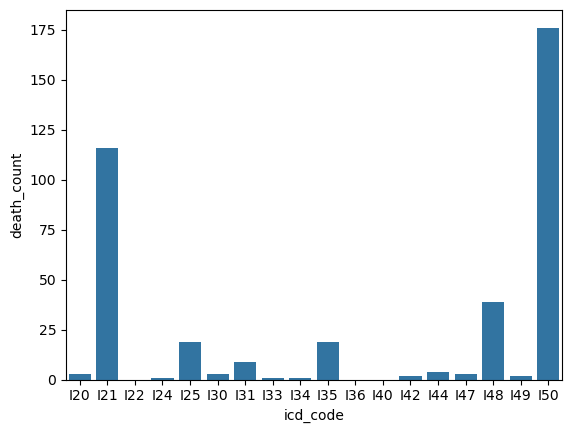

In [18]:
#to visualize the number of deaths for each icd_code
sns.barplot(data=df_mortality,x="icd_code",y="death_count")

<Axes: xlabel='icd_code', ylabel='death_rate'>

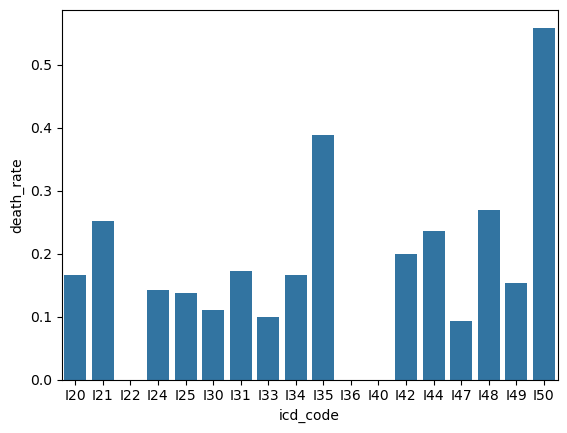

In [19]:
#to visualize the percentage of death for each icd_code
sns.barplot(data=df_mortality,x="icd_code",y="death_rate")

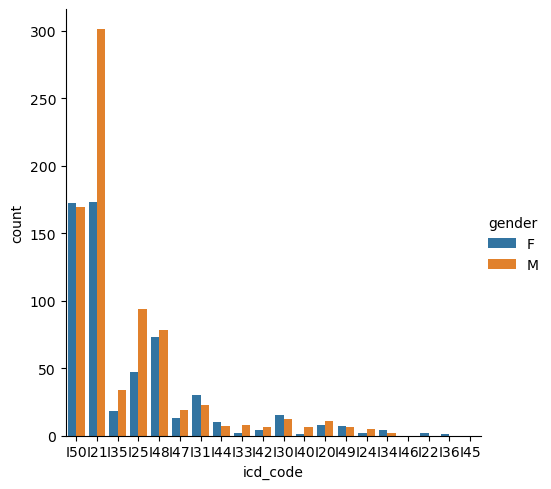

In [20]:
#to visualize the number of female and men for each icd_code
sns.catplot(data=heart_diagnoses_df, x="icd_code", hue="gender",kind="count")

<Axes: xlabel='age', ylabel='Count'>

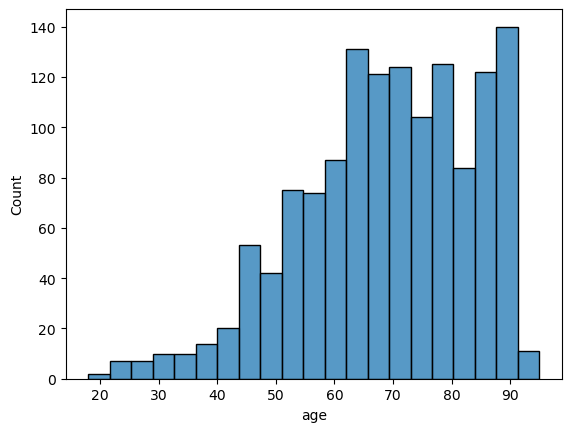

In [21]:
#to visualize the distribution of the ages
sns.histplot(heart_diagnoses_df, x="age")

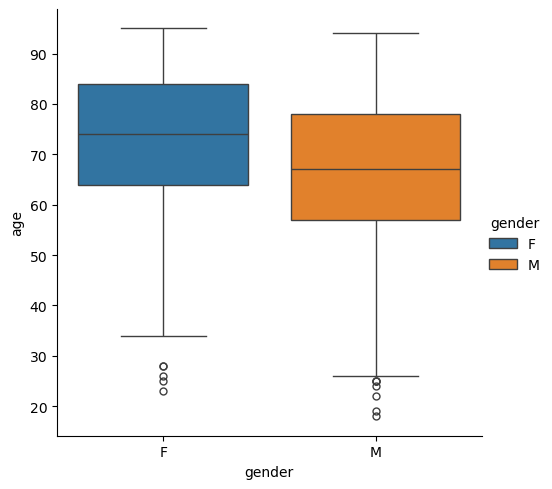

In [22]:
#another visualization to understand the age of female and men in the dataset
sns.catplot(data=heart_diagnoses_df, x="gender", y="age", hue="gender", kind="box")

<Axes: xlabel='icd_code', ylabel='age'>

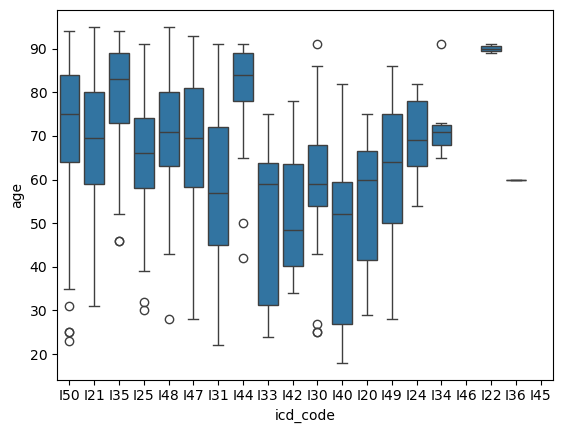

In [23]:
#to visualize for each icd_code the age of the patient 
sns.boxplot(data=heart_diagnoses_df,x="icd_code",y="age")
